In [ ]:
!jupyter nbconvert --to markdown RESEARCH.ipynb

[NbConvertApp] Converting notebook RESEARCH.ipynb to markdown
[NbConvertApp] Support files will be in RESEARCH_files/
[NbConvertApp] Making directory RESEARCH_files
[NbConvertApp] Writing 34019 bytes to RESEARCH.md


In [ ]:
# ==============================
# Bankruptcy Early Prediction Pipeline
# ==============================

# --- 1. Import Libraries ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from imblearn.over_sampling import SMOTE
import xgboost as xgb

import warnings
warnings.filterwarnings('ignore')

In [ ]:
# ==============================
# --- 2. Load the Dataset ---
# ==============================
file_path = "/content/Taiwan bankruptcy data.csv"

try:
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully!")
except FileNotFoundError:
    raise FileNotFoundError(f"Error: File '{file_path}' not found.")
except Exception as e:
    raise RuntimeError(f"Error loading dataset: {e}")

# ==============================
# --- 3. Initial Cleaning ---
# ==============================
df.columns = df.columns.str.strip()  # Remove extra spaces from column names

# Replace infinite values with NaN, then fill with median
for col in df.columns:
    if df[col].dtype in ['float64', 'int64']:
        df[col] = df[col].replace([np.inf, -np.inf], np.nan)
        df[col] = df[col].fillna(df[col].median())


Dataset loaded successfully!


Features shape: (6819, 95), Target shape: (6819,)
Target distribution:
Bankrupt?
0    96.77372
1     3.22628
Name: proportion, dtype: float64


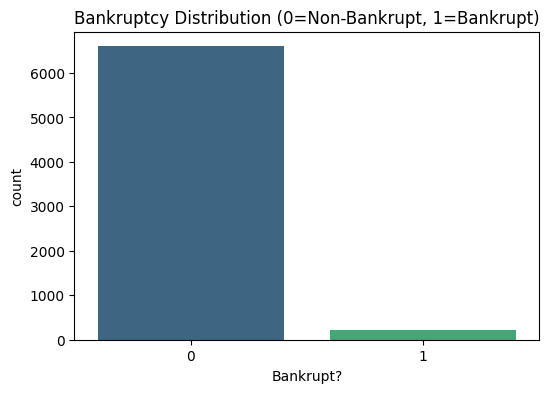

In [ ]:
# ==============================
# --- 4. Define Features and Target ---
# ==============================
target_column = 'Bankrupt?'
X = df.drop(columns=[target_column])
y = df[target_column]

print(f"Features shape: {X.shape}, Target shape: {y.shape}")
print("Target distribution:")
print(y.value_counts(normalize=True) * 100)

# Visualize class imbalance
plt.figure(figsize=(6,4))
sns.countplot(x=y, palette='viridis')
plt.title("Bankruptcy Distribution (0=Non-Bankrupt, 1=Bankrupt)")
plt.show()

# ==============================
# --- 5. Train-Test Split ---
# ==============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
# ==============================
# --- 6. Feature Scaling ---
# ==============================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==============================
# --- 7. Handle Class Imbalance (SMOTE) ---
# ==============================
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# ==============================
# --- 8. Model Training Function ---
# ==============================
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:,1] if hasattr(model, "predict_proba") else None

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan

    print(f"\n--- {model_name} ---")
    print(classification_report(y_test, y_pred))
    print(f"Accuracy: {acc:.4f}, Precision: {prec:.4f}, Recall: {rec:.4f}, F1: {f1:.4f}, ROC AUC: {auc:.4f}")
    return {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC AUC": auc
    }

In [ ]:
# ==============================
# --- 9. Train Multiple Models ---
# ==============================
results = {}
roc_curves = {}

# Logistic Regression
log_reg = LogisticRegression(random_state=42, solver='liblinear', class_weight='balanced')
log_reg.fit(X_train_resampled, y_train_resampled)
results['Logistic Regression'] = evaluate_model(log_reg, X_test_scaled, y_test, "Logistic Regression")
roc_curves['Logistic Regression'] = roc_curve(y_test, log_reg.predict_proba(X_test_scaled)[:,1])

# Random Forest
rf_clf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced', n_jobs=-1)
rf_clf.fit(X_train_resampled, y_train_resampled)
results['Random Forest'] = evaluate_model(rf_clf, X_test_scaled, y_test, "Random Forest")
roc_curves['Random Forest'] = roc_curve(y_test, rf_clf.predict_proba(X_test_scaled)[:,1])

# SVM
svm_clf = SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42)
svm_clf.fit(X_train_resampled, y_train_resampled)
results['SVM'] = evaluate_model(svm_clf, X_test_scaled, y_test, "SVM")
roc_curves['SVM'] = roc_curve(y_test, svm_clf.predict_proba(X_test_scaled)[:,1])

# KNN
knn_clf = KNeighborsClassifier(n_neighbors=5)
knn_clf.fit(X_train_resampled, y_train_resampled)
results['KNN'] = evaluate_model(knn_clf, X_test_scaled, y_test, "KNN")
roc_curves['KNN'] = roc_curve(y_test, knn_clf.predict_proba(X_test_scaled)[:,1])

# XGBoost
scale_pos_weight_val = (y_train_resampled.value_counts()[0] / y_train_resampled.value_counts()[1])
xgb_clf = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss',
                            random_state=42, n_estimators=200, learning_rate=0.1,
                            scale_pos_weight=scale_pos_weight_val, use_label_encoder=False)
xgb_clf.fit(X_train_resampled, y_train_resampled)
results['XGBoost'] = evaluate_model(xgb_clf, X_test_scaled, y_test, "XGBoost")
roc_curves['XGBoost'] = roc_curve(y_test, xgb_clf.predict_proba(X_test_scaled)[:,1])

# Voting Classifier
voting_clf = VotingClassifier(estimators=[
    ('lr', log_reg),
    ('rf', rf_clf),
    ('xgb', xgb_clf)
], voting='soft', n_jobs=-1)
voting_clf.fit(X_train_resampled, y_train_resampled)
results['Voting Classifier'] = evaluate_model(voting_clf, X_test_scaled, y_test, "Voting Classifier")
roc_curves['Voting Classifier'] = roc_curve(y_test, voting_clf.predict_proba(X_test_scaled)[:,1])



--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.99      0.89      0.94      1320
           1       0.19      0.80      0.30        44

    accuracy                           0.88      1364
   macro avg       0.59      0.84      0.62      1364
weighted avg       0.97      0.88      0.92      1364

Accuracy: 0.8827, Precision: 0.1882, Recall: 0.7955, F1: 0.3043, ROC AUC: 0.9170

--- Random Forest ---
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1320
           1       0.43      0.61      0.50        44

    accuracy                           0.96      1364
   macro avg       0.71      0.79      0.74      1364
weighted avg       0.97      0.96      0.96      1364

Accuracy: 0.9611, Precision: 0.4286, Recall: 0.6136, F1: 0.5047, ROC AUC: 0.9429

--- SVM ---
              precision    recall  f1-score   support

           0       0.99      0.90      0.94      1320
          

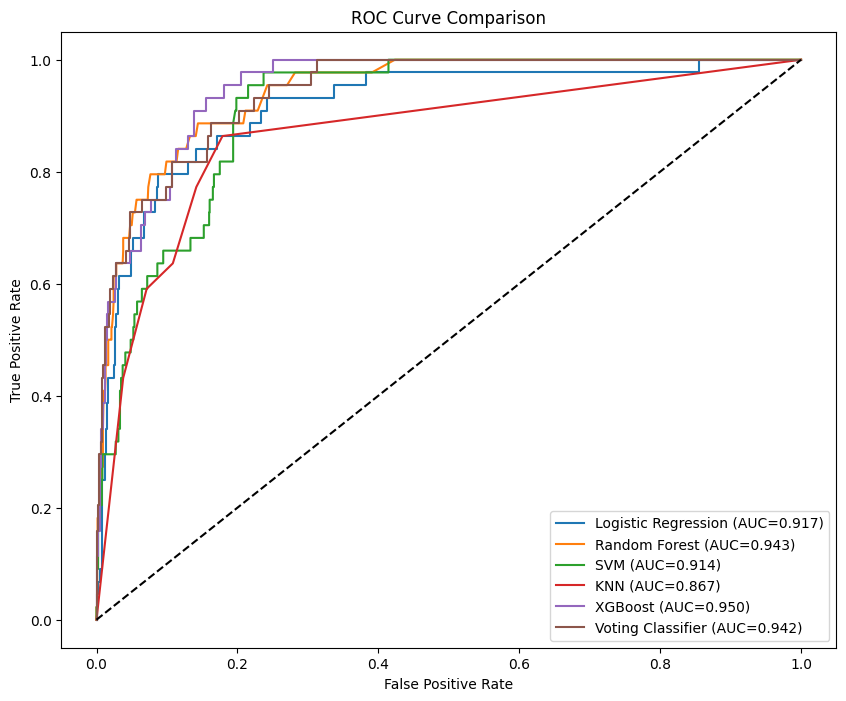

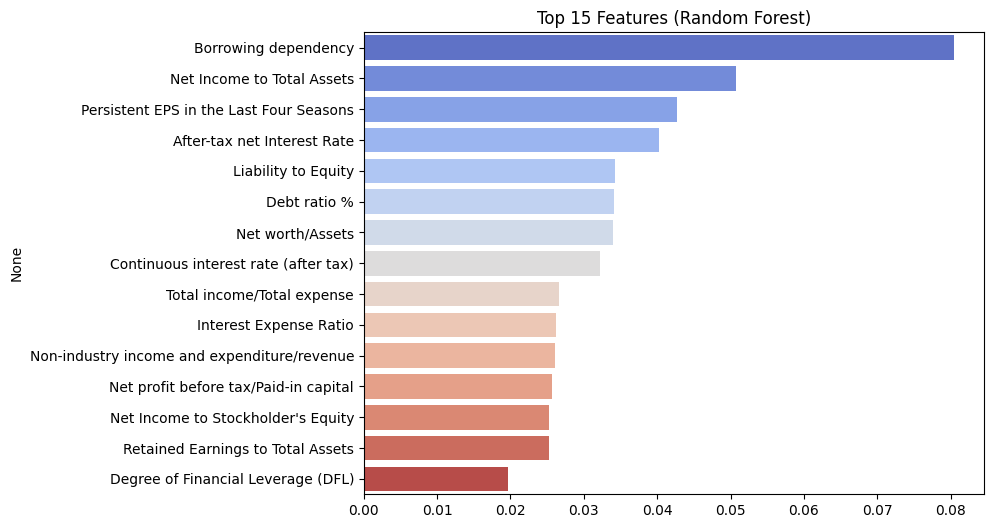

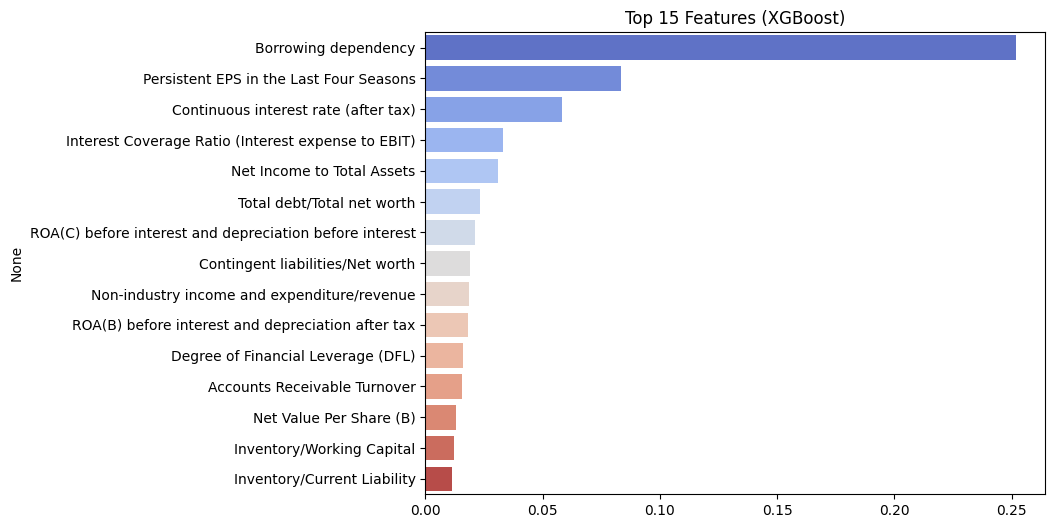


--- Early Prediction Explanation ---

The dataset contains financial ratios like ROA, Debt Ratio, Current Ratio, Cash Flow Rate, etc.
These are leading indicators — distress often shows in these ratios months or even years before actual bankruptcy.
By training on historical cases, the model learns subtle patterns that appear early.
Even without explicit time-series, the 'snapshots' of many companies at different stages let the model detect early warning signs.
This means you can flag risky companies before bankruptcy occurs, enabling preventive action.



In [ ]:
# ==============================
# --- 10. ROC Curve Plot ---
# ==============================
plt.figure(figsize=(10,8))
for name, (fpr, tpr, _) in roc_curves.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC={results[name]['ROC AUC']:.3f})")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

# ==============================
# --- 11. Feature Importance ---
# ==============================
if hasattr(rf_clf, 'feature_importances_'):
    rf_importance = pd.Series(rf_clf.feature_importances_, index=X.columns).sort_values(ascending=False)[:15]
    plt.figure(figsize=(8,6))
    sns.barplot(x=rf_importance.values, y=rf_importance.index, palette='coolwarm')
    plt.title("Top 15 Features (Random Forest)")
    plt.show()

if hasattr(xgb_clf, 'feature_importances_'):
    xgb_importance = pd.Series(xgb_clf.feature_importances_, index=X.columns).sort_values(ascending=False)[:15]
    plt.figure(figsize=(8,6))
    sns.barplot(x=xgb_importance.values, y=xgb_importance.index, palette='coolwarm')
    plt.title("Top 15 Features (XGBoost)")
    plt.show()

# ==============================
# --- 12. How This Enables Early Prediction ---
# ==============================
print("\n--- Early Prediction Explanation ---")
print("""
The dataset contains financial ratios like ROA, Debt Ratio, Current Ratio, Cash Flow Rate, etc.
These are leading indicators — distress often shows in these ratios months or even years before actual bankruptcy.
By training on historical cases, the model learns subtle patterns that appear early.
Even without explicit time-series, the 'snapshots' of many companies at different stages let the model detect early warning signs.
This means you can flag risky companies before bankruptcy occurs, enabling preventive action.
""")

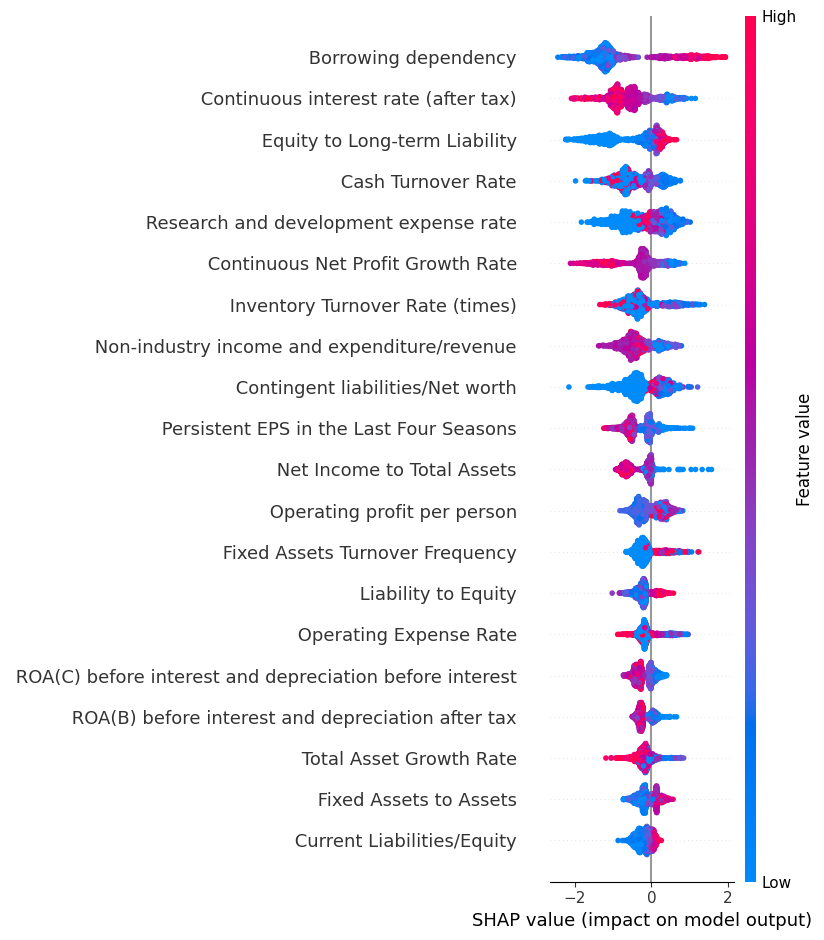

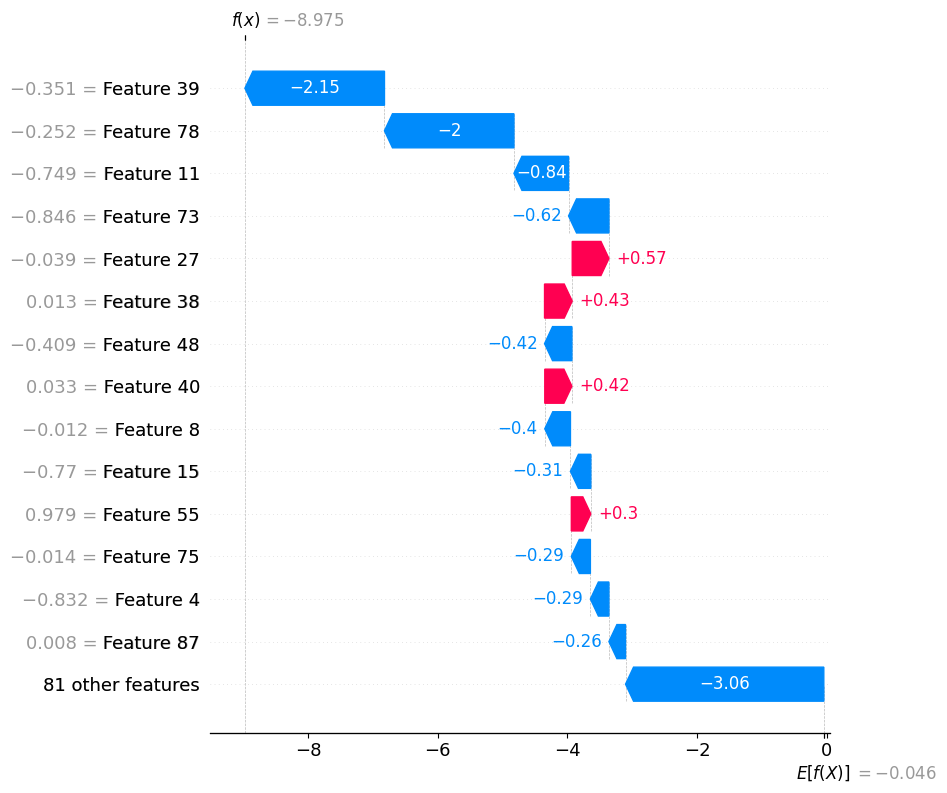

Best RF params: {'class_weight': 'balanced', 'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}

--- Random Forest (Tuned) ---
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1320
           1       0.42      0.61      0.50        44

    accuracy                           0.96      1364
   macro avg       0.70      0.79      0.74      1364
weighted avg       0.97      0.96      0.96      1364

Accuracy: 0.9604, Precision: 0.4219, Recall: 0.6136, F1: 0.5000, ROC AUC: 0.9477


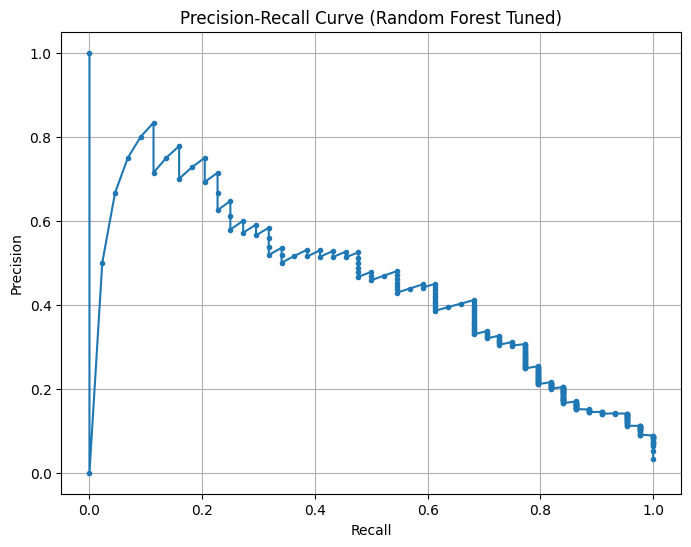

Threshold: 0.000, Precision: 0.032, Recall: 1.000


In [ ]:
# Install SHAP if not already installed
!pip install shap

import shap
from sklearn.model_selection import GridSearchCV

# ----------- SHAP Explanation for XGBoost -----------

# Initialize explainer using training data (use X_train_resampled)
explainer = shap.Explainer(xgb_clf)
shap_values = explainer(X_test_scaled)

# Summary plot: global feature importance and effect
shap.summary_plot(shap_values, X_test, feature_names=X.columns)

# For a single instance explanation
idx = 10  # example index
shap.waterfall_plot(shap_values[idx], max_display=15)

# ----------- Hyperparameter Tuning for Random Forest -----------

param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'class_weight': ['balanced']
}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                       param_grid=param_grid_rf,
                       cv=3,
                       scoring='recall',
                       n_jobs=-1)
grid_rf.fit(X_train_resampled, y_train_resampled)

print("Best RF params:", grid_rf.best_params_)

# Evaluate best RF after tuning
best_rf = grid_rf.best_estimator_
evaluate_model(best_rf, X_test_scaled, y_test, "Random Forest (Tuned)")

# ----------- Threshold Tuning & Precision-Recall Curve -----------

from sklearn.metrics import precision_recall_curve

y_proba_best_rf = best_rf.predict_proba(X_test_scaled)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_test, y_proba_best_rf)

# Plot Precision-Recall Curve
plt.figure(figsize=(8,6))
plt.plot(recall, precision, marker='.')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Random Forest Tuned)')
plt.grid(True)
plt.show()

# Select threshold with best recall for acceptable precision (example)
for p, r, t in zip(precision, recall, thresholds):
    if r > 0.85: # example recall threshold
        print(f"Threshold: {t:.3f}, Precision: {p:.3f}, Recall: {r:.3f}")
        break


In [ ]:
!pip install imbalanced-learn

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import ADASYN
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

# Step 1: Load your dataset
# Replace 'your_dataset.csv' with your actual file path or loading method
data = pd.read_csv("/content/Taiwan bankruptcy data.csv")

# Step 2: Define features and target
target_col = 'Bankrupt?'
X = data.drop(columns=[target_col])
y = data[target_col]

# Step 3: Split into training and test sets (stratify to keep class distribution)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 4: Scale features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 5: Oversample training data using ADASYN
adasyn = ADASYN(random_state=42)
X_train_adasyn, y_train_adasyn = adasyn.fit_resample(X_train_scaled, y_train)

# Step 6: Initialize Balanced Bagging Classifier with DecisionTree base estimator
bbc = BalancedBaggingClassifier(
    estimator=DecisionTreeClassifier(),
    sampling_strategy='auto',
    replacement=False,
    random_state=42,
    n_estimators=50,
    n_jobs=-1
)


# Step 7: Train classifier on the oversampled training data
bbc.fit(X_train_adasyn, y_train_adasyn)

# Step 8: Make predictions on the test data
y_pred_bbc = bbc.predict(X_test_scaled)

# Step 9: Print evaluation metrics
print("Balanced Bagging Classifier Results:")
print(classification_report(y_test, y_pred_bbc))


Balanced Bagging Classifier Results:
              precision    recall  f1-score   support

           0       0.98      0.97      0.97      1320
           1       0.31      0.48      0.38        44

    accuracy                           0.95      1364
   macro avg       0.65      0.72      0.68      1364
weighted avg       0.96      0.95      0.95      1364



In [ ]:
# =============================
# 1. Import Libraries
# =============================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix
import shap

# =============================
# 2. Load Dataset
# =============================
# Replace with your file name
df = "/content/Taiwan bankruptcy data.csv"




In [ ]:
print(X.columns.tolist())


[' ROA(C) before interest and depreciation before interest', ' ROA(A) before interest and % after tax', ' ROA(B) before interest and depreciation after tax', ' Operating Gross Margin', ' Realized Sales Gross Margin', ' Operating Profit Rate', ' Pre-tax net Interest Rate', ' After-tax net Interest Rate', ' Non-industry income and expenditure/revenue', ' Continuous interest rate (after tax)', ' Operating Expense Rate', ' Research and development expense rate', ' Cash flow rate', ' Interest-bearing debt interest rate', ' Tax rate (A)', ' Net Value Per Share (B)', ' Net Value Per Share (A)', ' Net Value Per Share (C)', ' Persistent EPS in the Last Four Seasons', ' Cash Flow Per Share', ' Revenue Per Share (Yuan ¥)', ' Operating Profit Per Share (Yuan ¥)', ' Per Share Net profit before tax (Yuan ¥)', ' Realized Sales Gross Profit Growth Rate', ' Operating Profit Growth Rate', ' After-tax Net Profit Growth Rate', ' Regular Net Profit Growth Rate', ' Continuous Net Profit Growth Rate', ' Tota

In [ ]:
# =============================
# 4. Early-Warning Feature Engineering
# =============================

# Remove leading/trailing whitespace from column names
X.columns = X.columns.str.strip()

# Liquidity signals
X['Liquidity_Index'] = (X['Current Ratio'] + X['Quick Ratio']) / 2

# Leverage signals
X['Leverage_Index'] = (X['Debt ratio %'] +
                      X['Borrowing dependency'] +
                      X['Long-term fund suitability ratio (A)']) / 3

# Profitability signals
X['Profitability_Index'] = (X['ROA(C) before interest and depreciation before interest'] +
                           X['Operating Profit Rate'] +
                           X['Net profit before tax/Paid-in capital']) / 3

# Cash flow signals
X['Cashflow_Index'] = (X['Cash Flow to Sales'] +
                      X['Cash Flow to Liability'] +
                      X['CFO to Assets']) / 3

# Composite Early Warning Score
X['EarlyWarningScore'] = (1.2 * X['Liquidity_Index'] +
                         1.4 * X['Profitability_Index'] +
                         3.3 * X['Cashflow_Index'] -
                         1.0 * X['Leverage_Index'])
